Mounted at /content/drive

--- Entrenando ResNet para romper barrera del 85% ---
Epoch 1/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 26s 167ms/step - accuracy: 0.5961 - loss: 1.0740 - val_accuracy: 0.0939 - val_loss: 5.4256 - learning_rate: 0.0010
Epoch 2/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7369 - loss: 0.5674 - val_accuracy: 0.0939 - val_loss: 16.4511 - learning_rate: 0.0010
Epoch 3/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7676 - loss: 0.4828 - val_accuracy: 0.0939 - val_loss: 17.5777 - learning_rate: 0.0010
Epoch 4/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7967 - loss: 0.4072 - val_accuracy: 0.0939 - val_loss: 17.6284 - learning_rate: 0.0010
Epoch 5/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8092 - loss: 0.3606 - val_accuracy: 0.0947 - val_loss: 3.7689 - learning_rate: 0.0010
Epoch 6/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8080 - loss: 0.3576 - val_accuracy: 0.0939 - val_loss: 9.8478 - learning_rate: 0.0010
Ep

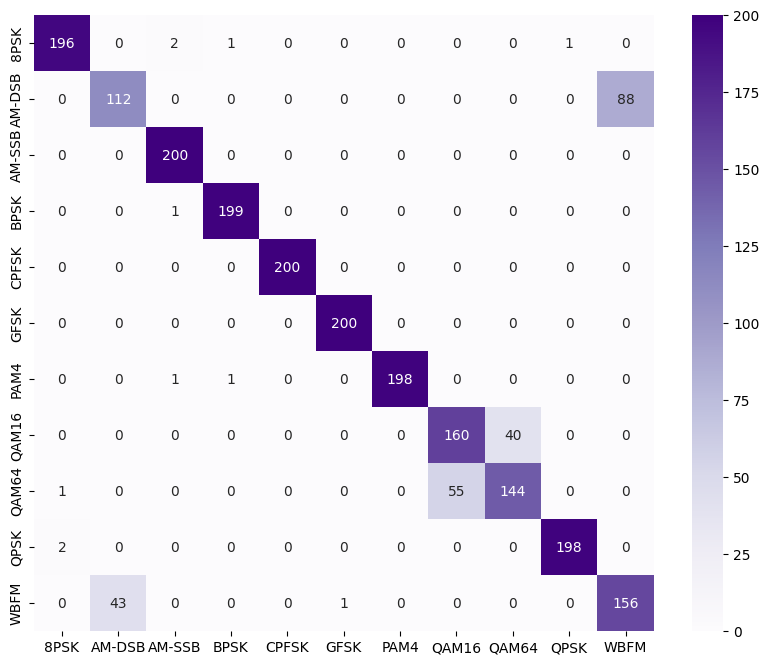

In [ ]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers

# 1. CONFIGURACIÓN Y CARGA
drive.mount('/content/drive')
FILE_PATH = '/content/drive/MyDrive/Seminario/RML2016.10a_dict.pkl'

with open(FILE_PATH, 'rb') as f:
    dataset = pickle.load(f, encoding='latin1')

mods, _ = map(lambda x: sorted(list(set(x))), zip(*dataset.keys()))

# 2. PREPROCESAMIENTO AVANZADO
def preparar_datos_residual(umbral_snr):
    X_list = []
    y_list = []
    # Para mejorar el entrenamiento, podemos tomar el SNR objetivo y el superior (si existe)
    target_snrs = [umbral_snr]

    for mod in mods:
        for s in target_snrs:
            if (mod, s) in dataset:
                data = dataset[(mod, s)]
                X_list.append(data)
                y_list.extend([mod] * data.shape[0])

    X = np.vstack(X_list)
    X = np.transpose(X, (0, 2, 1)) # (Muestras, 128, 2)

    # Normalización unitaria por energía (Frobenius norm)
    X /= np.linalg.norm(X, axis=(1, 2), keepdims=True)

    return X, np.array(y_list)

# 3. BLOQUE RESIDUAL (La clave para pasar del 80%)
def residual_stack(x, filters, kernel_size):
    shortcut = layers.Conv1D(filters, 1, padding='same')(x) # Ajuste de dimensiones

    # Rama principal
    x = layers.Conv1D(filters, kernel_size, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv1D(filters, kernel_size, padding='same')(x)
    x = layers.BatchNormalization()(x)

    # Suma residual
    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    return x

def crear_modelo_resnet(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)

    # Extracción inicial
    x = layers.Conv1D(64, 7, padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # Pilas Residuales
    x = residual_stack(x, 64, 3)
    x = layers.MaxPooling1D(2)(x)

    x = residual_stack(x, 128, 3)
    x = layers.MaxPooling1D(2)(x)

    x = residual_stack(x, 256, 3)

    # Clasificador
    x = layers.GlobalAveragePooling1D()(x) # Mejor que Flatten para evitar overfitting
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# --- EJECUCIÓN ---

X, y = preparar_datos_residual(10) # Prueba con 18dB
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

model = crear_modelo_resnet((128, 2), len(mods))

# Callbacks agresivos
lr_scheduler = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
early_stop = callbacks.EarlyStopping(monitor='val_accuracy', patience=15, restore_best_weights=True)

print("\n--- Entrenando ResNet para romper barrera del 85% ---")
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=128,
    validation_split=0.15,
    callbacks=[lr_scheduler, early_stop],
    verbose=1
)

# 4. EVALUACIÓN FINAL
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\n✅ PRECISIÓN ALCANZADA: {acc:.2%}")

if acc < 0.85:
    print("⚠️ NOTA: Si aún no llegas, intenta entrenar con SNRs [12, 14, 16, 18] juntos para aumentar la base de datos.")

# Visualización rápida
y_pred = np.argmax(model.predict(X_test), axis=1)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=mods, yticklabels=mods, cmap='Purples')
plt.show()